# 03 · Evaluate: reproduce every result in Section 7

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/upretisaurav/doc-verify/blob/v1.0-submission/notebooks/03_evaluate.ipynb)

This notebook reproduces the report's results from the saved predictions, in about a minute on CPU:

- the document-type tables, per-class F1 and confusion matrices;
- the authenticity tables and breakdowns;
- the McNemar tests;
- the validation-only diagnostics.

It then checks the key numbers against the values printed in the report.

**Modes.** Set the flag in the next cell:

- `RE_PREDICT = False` (default) uses the predictions saved in `results/` when the test split was evaluated.
- `RE_PREDICT = True` needs a GPU runtime. It downloads the data bundle and the four checkpoints from the GitHub
  release, rebuilds the CLIP text-feature cache, predicts the test split again, and compares the new predictions with
  the saved ones. This takes about 5–10 minutes on a T4.

| Section | Backs report section |
|---|---|
| 1. The frozen test plan | 7 (protocol) |
| 2. Predictions | 7 |
| 3. Document type | 7, Table 1, Table 1b, Appendix A, Figure 1 |
| 4. Authenticity | 7, Tables 2 and 3 |
| 5. McNemar tests | 7 |
| 6. Checks against the report | – |
| 7. Diagnostic runs (validation only) | 5.4, 7 |

Run order: `01_data` → `02_train` → `03_evaluate`. Each notebook also runs on its own, from the saved outputs.

In [1]:
RE_PREDICT = True  # True: re-predict the test split from the released checkpoints (GPU runtime needed)

## Setup

Runs in a fresh Colab runtime or locally from a clone of the repository.

**On Colab**, this cell does three things:

1. It gets the code: it clones the repository at the submission tag, or unpacks the code zip if `CODE_ZIP` is set
   (for when the repository is not public).
2. It installs the few packages Colab lacks, pinned in `requirements-colab.txt`. Colab's own torch, NumPy and pandas
   are kept, and their versions are printed below.
3. It puts the code on the import path.

**Locally**, the cell only finds the repository root. Install with `uv sync` first.

In [2]:
REPO_URL = 'https://github.com/upretisaurav/doc-verify.git'
TAG = 'v1.0-submission'
CODE_ZIP = None  # if the repository is not public: path to the submitted code zip, e.g. '/content/doc-verify.zip'

import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    ROOT = Path('/content/doc-verify')
    if not ROOT.exists():
        if CODE_ZIP:
            subprocess.run(['unzip', '-q', CODE_ZIP, '-d', '/content'], check=True)
        else:
            subprocess.run(['git', 'clone', '-q', '--depth', '1', '--branch', TAG, REPO_URL, str(ROOT)], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(ROOT / 'requirements-colab.txt')],
                   check=True)
else:
    ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
for path in (ROOT / 'src', ROOT):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
os.chdir(ROOT)

import importlib.metadata
import platform

import torch
import transformers

transformers.logging.set_verbosity_error()  # hide checkpoint-loading reports
transformers.logging.disable_progress_bar()

gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none'
print(f'Python {platform.python_version()} | torch {torch.__version__} | GPU: {gpu}')
print({p: importlib.metadata.version(p) for p in ('timm', 'transformers', 'scikit-learn', 'numpy', 'pandas')})

Python 3.13.16 | torch 2.14.1+cu130 | GPU: Tesla T4
{'timm': '1.0.30', 'transformers': '5.18.0', 'scikit-learn': '1.9.1', 'numpy': '2.4.6', 'pandas': '2.2.3'}


## 1. The frozen test plan

Every modelling choice was fixed on the training and validation splits and written into `reports/test_plan.md`. That
file and the decision thresholds in `reports/val_thresholds.json` were committed before the test split was first
loaded (git commit [`68d7058`](https://github.com/upretisaurav/doc-verify/commit/68d7058)).

Until then, `doc_verify.data.load_pages` refused to load the test split: it raises an error unless `TEST_SET_UNLOCKED`
in `doc_verify/config.py` is set. The flag was set once, in the next commit ([`ed4b83f`](https://github.com/upretisaurav/doc-verify/commit/ed4b83f)), and the test split was then
evaluated once. Nothing below was chosen after seeing test results.

In [3]:
import json

from IPython.display import Markdown, display

from doc_verify.config import RESULTS_DIR, TEST_SET_UNLOCKED

thresholds = json.loads((ROOT / 'reports' / 'val_thresholds.json').read_text())
print('TEST_SET_UNLOCKED =', TEST_SET_UNLOCKED)
print('Decision thresholds (chosen on validation, best balanced accuracy):', thresholds)
plan = (ROOT / 'reports' / 'test_plan.md').read_text()
display(Markdown(plan[plan.index('## Metrics'):plan.index('## Validation findings')]))

TEST_SET_UNLOCKED = True
Decision thresholds (chosen on validation, best balanced accuracy): {'fused': 0.3989332, 'fused_no_kind': 0.48473832, 'image_vit': 0.6995624, 'tfidf': 0.3936583786574854, 'rule_checker': 1.0}


## Metrics and planned analyses

1. **Document type** (Tobacco3482 test, 521 pages): accuracy and macro-F1 with 95% bootstrap intervals (2,000
   resamples of pages, seed 0); a per-class confusion matrix for every type model.
2. **Authenticity** (SAD-Syn test, 450 pages, 225 pairs): AUC with 95% intervals from 2,000 resamples of clean/altered
   pairs (seed 0); accuracy and macro-F1 at the thresholds above.
3. **Authenticity breakdowns**, each over both partners of the pairs in the group, with pair-bootstrap intervals: by
   inconsistency kind, by document type, and by whether OCR read the altered value (`altered_value_ocr_ok`).
4. **Kind** macro-F1 (five classes) for the models with a kind head and the rule checker.
5. **McNemar's test** (exact) on per-page right/wrong decisions, with Holm correction across the three tests:
   - type: fused vs image-only ViT (the stronger single-modality model on validation);
   - authenticity: fused vs rule checker, at the thresholds above;
   - type: fused vs fused λ₂ = 0 (the kind-head ablation).
   Clean and altered partners share a template and scan noise, so the authenticity test treats pages as independent
   when they are not fully; this is stated alongside the result.



## 2. Predictions

There is one file per model, with one row per test page: the true labels, the predicted type, the authenticity score
(the probability of "altered"; for the rule checker, the number of rules broken) and the predicted kind.

- **Neural models:** predicted on Colab from each run's best validation checkpoint (`doc_verify.train.predict_run`).
- **TF-IDF, CLIP zero-shot, rule checker:** predicted locally (`doc_verify.baselines`, `doc_verify.rule_checker`).

The labels in every file are checked against the page table: the manifests committed in `results/manifests`.

In [4]:
import pandas as pd

from doc_verify.data import all_pages

pages = all_pages(RESULTS_DIR / 'manifests')
test = pages[pages.split == 'test'].set_index('page_index')

NAMES = {
    'fused': 'Fused (main)', 'fused_no_kind': 'Fused, λ₂ = 0', 'image_vit': 'Image-only ViT',
    'resnet18': 'ResNet18 scratch', 'tfidf': 'TF-IDF + LR', 'clip_zero_shot': 'CLIP zero-shot',
    'rule_checker': 'Rule checker',
}
predictions = {name: pd.read_csv(RESULTS_DIR / 'test_predictions' / f'{name}.csv') for name in NAMES}
for name, p in predictions.items():
    assert p.page_index.isin(test.index).all(), name
    for column in ('type_label', 'auth_label', 'kind_label'):
        if column in p:
            assert (p[column].to_numpy() == test.loc[p.page_index, column].to_numpy()).all(), (name, column)
print({name: len(p) for name, p in predictions.items()})
print('test split:', (test.source == 'tobacco3482').sum(), 'Tobacco3482 pages,', (test.source == 'sad_syn').sum(),
      'SAD-Syn pages')

{'fused': 971, 'fused_no_kind': 971, 'image_vit': 971, 'resnet18': 521, 'tfidf': 971, 'clip_zero_shot': 521, 'rule_checker': 450}
test split: 521 Tobacco3482 pages, 450 SAD-Syn pages


### 2b. Optional: re-predict from the checkpoints (`RE_PREDICT = True`, GPU)

This step checks that the released checkpoints give the saved predictions:

1. Download the 224 × 224 data bundle and the checkpoints from the GitHub release.
2. Encode every page's OCR text with the frozen CLIP text encoder (Section 4.4).
3. Predict the test split with each run's own configuration.

Expect identical type predictions and authenticity scores equal to within fp16 rounding. The saved predictions are
used for everything below either way.

In [5]:
if RE_PREDICT:
    from doc_verify.assets import CHECKPOINTS, fetch_bundle, fetch_checkpoint
    from doc_verify.config import DATA_DIR
    from doc_verify.train import predict_run
    from doc_verify.windows import TEXT_WINDOWS, cache_text_features

    bundle = fetch_bundle()
    bundle_pages = all_pages(bundle)
    cache = DATA_DIR / 'clip_text'
    if not Path(f'{cache}_features.npy').exists():
        texts = [(bundle / p.source / p.text_path).read_text(encoding='utf-8') for p in bundle_pages.itertuples()]
        cache_text_features(texts, str(cache), TEXT_WINDOWS)
    for name in CHECKPOINTS:
        fresh = predict_run(fetch_checkpoint(name), 'test', data_root=bundle, text_cache=str(cache))
        both = predictions[name].merge(fresh, on='page_index', suffixes=('_saved', '_new'))
        typed = both[both.type_label_saved >= 0]
        authed = both[both.auth_label_saved >= 0]
        print(f"{name}: {len(both)} pages | type predictions equal: {(typed.type_pred_saved == typed.type_pred_new).mean():.1%}"
              + (f" | max authenticity-score difference: {(authed.auth_score_saved - authed.auth_score_new).abs().max():.4f}"
                 if len(authed) else ''))
else:
    print('RE_PREDICT is False: using the saved predictions.')

downloading doc_verify_bundle.zip ...


downloading fused.pt ...
fused: 971 pages | type predictions equal: 100.0% | max authenticity-score difference: 0.0000
downloading fused_no_kind.pt ...
fused_no_kind: 971 pages | type predictions equal: 100.0% | max authenticity-score difference: 0.0000
downloading image_vit.pt ...
image_vit: 971 pages | type predictions equal: 100.0% | max authenticity-score difference: 0.0000
downloading resnet18.pt ...
resnet18: 521 pages | type predictions equal: 100.0%


## 3. Document type (Tobacco3482 test split, 521 pages)

- **Table 1:** accuracy and macro-F1 for every type model, with 95% bootstrap intervals for macro-F1 (2,000
  resamples of pages, seed 0; `evaluate.type_bootstrap_f1`).
- **Appendix A:** F1 per class.
- **Figure 1:** confusion matrices.

In [6]:
from sklearn.metrics import accuracy_score, f1_score

from doc_verify.data import MISSING, TYPE_CLASSES
from doc_verify.evaluate import type_bootstrap_f1

TYPE_MODELS = ['fused', 'fused_no_kind', 'image_vit', 'resnet18', 'tfidf', 'clip_zero_shot']
rows = []
for name in TYPE_MODELS:
    typed = predictions[name][predictions[name].type_label != MISSING]
    f1, low, high = type_bootstrap_f1(predictions[name])
    rows.append({'model': NAMES[name], 'pages': len(typed), 'accuracy': accuracy_score(typed.type_label, typed.type_pred),
                 'macro_f1': f1, 'f1_ci_low': low, 'f1_ci_high': high})
type_table = pd.DataFrame(rows).set_index('model')
type_table.round(3)

,pages,accuracy,macro_f1,f1_ci_low,f1_ci_high
model,,,,,
Fused (main),521,0.864,0.845,0.810,0.877
"Fused, λ₂ = 0",521,0.885,0.878,0.846,0.905
Image-only ViT,521,0.873,0.848,0.808,0.881
ResNet18 scratch,521,0.580,0.559,0.512,0.601
TF-IDF + LR,521,0.785,0.738,0.692,0.777
CLIP zero-shot,521,0.430,0.418,0.377,0.457


In [7]:
per_class = pd.DataFrame({
    NAMES[name]: f1_score(p.type_label, p.type_pred, average=None, labels=range(len(TYPE_CLASSES)))
    for name in ['fused', 'fused_no_kind', 'image_vit', 'tfidf']
    for p in [predictions[name][predictions[name].type_label != MISSING]]
}, index=TYPE_CLASSES)
per_class.insert(0, 'test pages', test[test.source == 'tobacco3482'].doc_type.value_counts().reindex(TYPE_CLASSES))
per_class.round(2)  # Appendix A; Table 1b shows email, advertisement, resume, report and scientific

,test pages,Fused (main),"Fused, λ₂ = 0",Image-only ViT,TF-IDF + LR
advertisement,35,0.94,0.96,0.96,0.69
email,90,0.97,0.98,0.98,0.96
form,64,0.86,0.90,0.88,0.80
letter,85,0.90,0.86,0.88,0.76
memo,93,0.86,0.91,0.91,0.82
news,28,0.88,0.89,0.88,0.82
note,30,0.80,0.87,0.82,0.47
report,39,0.73,0.73,0.69,0.37
resume,18,0.92,0.97,0.87,0.94
scientific,39,0.60,0.69,0.61,0.75


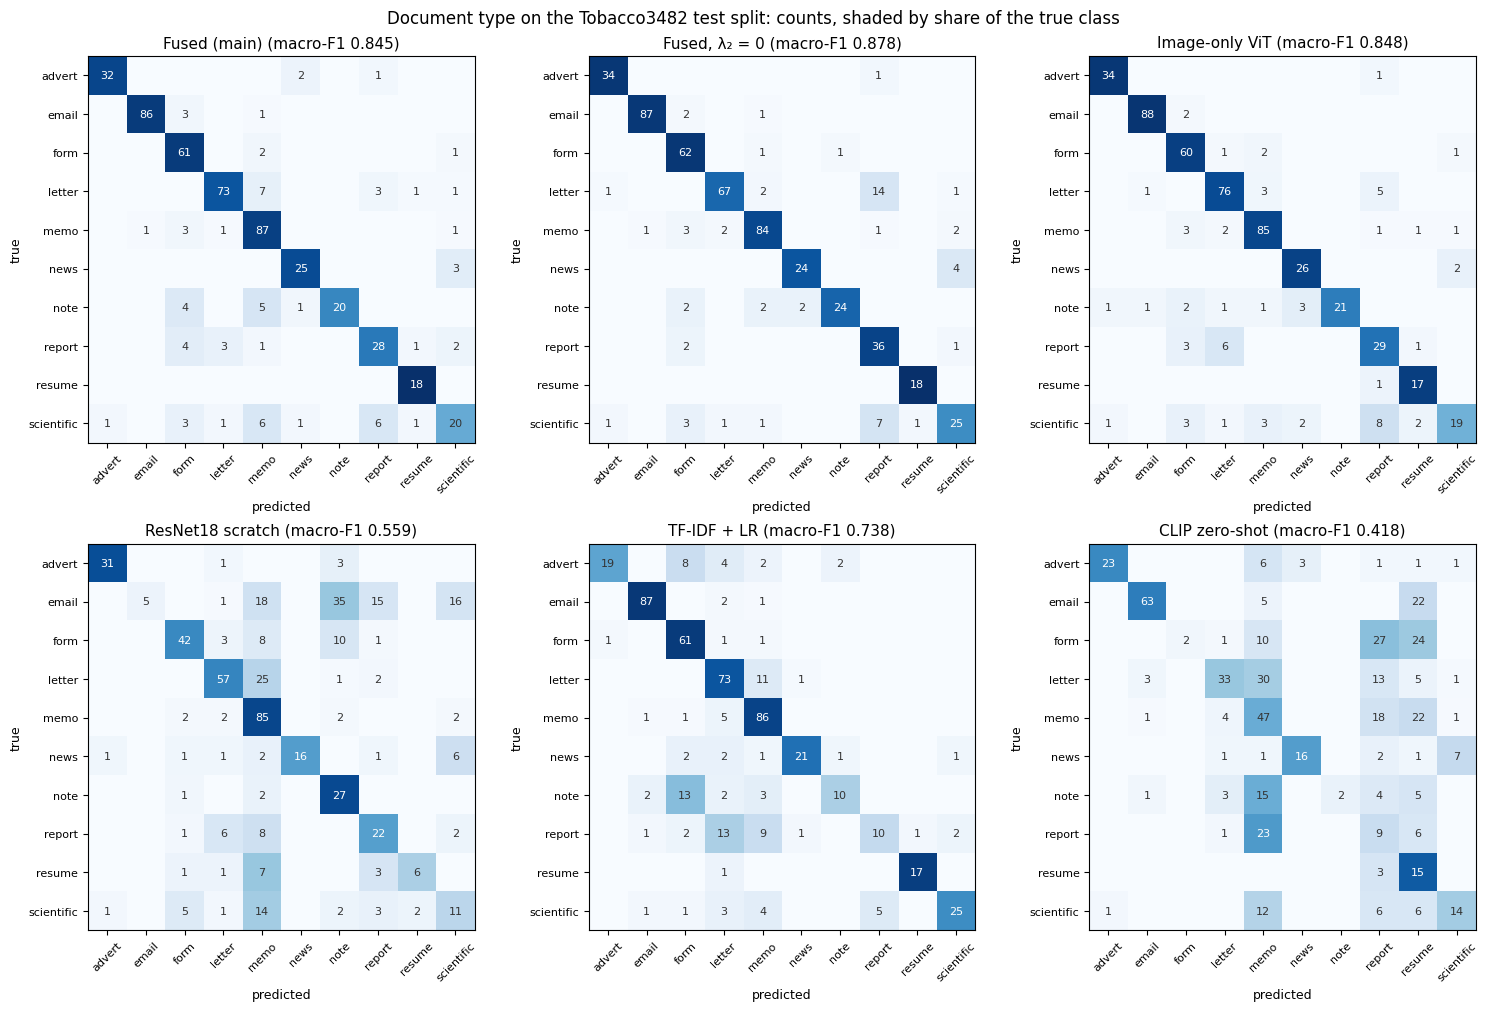

In [8]:
import matplotlib.pyplot as plt

from doc_verify.config import FIGURES_DIR
from doc_verify.evaluate import type_confusion

fig, axes = plt.subplots(2, 3, figsize=(15, 10), constrained_layout=True)
short = ['advert', 'email', 'form', 'letter', 'memo', 'news', 'note', 'report', 'resume', 'scientific']
for ax, name in zip(axes.flat, TYPE_MODELS):
    counts = type_confusion(predictions[name])
    share = counts.div(counts.sum(axis=1), axis=0)
    ax.imshow(share, cmap='Blues', vmin=0, vmax=1)
    for i in range(len(TYPE_CLASSES)):
        for j in range(len(TYPE_CLASSES)):
            if counts.iat[i, j]:
                ax.text(j, i, counts.iat[i, j], ha='center', va='center', fontsize=8,
                        color='white' if share.iat[i, j] > 0.55 else '#333333')
    ax.set_title(f"{NAMES[name]} (macro-F1 {type_table.loc[NAMES[name], 'macro_f1']:.3f})", fontsize=11)
    ax.set_xticks(range(len(short)), short, rotation=45, fontsize=8)
    ax.set_yticks(range(len(short)), short, fontsize=8)
    ax.set_xlabel('predicted', fontsize=9)
    ax.set_ylabel('true', fontsize=9)
fig.suptitle('Document type on the Tobacco3482 test split: counts, shaded by share of the true class', fontsize=12)
fig.savefig(FIGURES_DIR / 'test_type_confusion.png', dpi=200)
plt.show()

## 4. Authenticity (SAD-Syn test split, 450 pages = 225 clean/altered pairs)

**Table 2.** AUC with a 95% interval from 2,000 bootstrap resamples of *pairs* (seed 0; `evaluate.pair_bootstrap_auc`).
Resampling pairs rather than pages is used because a pair's two pages share a template and scan noise.

Accuracy and macro-F1 use the thresholds frozen on validation. Kind macro-F1 is over the five classes (clean plus
four kinds).

In [9]:
from doc_verify.data import KIND_CLASSES
from doc_verify.evaluate import pair_bootstrap_auc, pair_table

AUTH_MODELS = ['fused', 'fused_no_kind', 'image_vit', 'tfidf', 'rule_checker']
rows = []
for name in AUTH_MODELS:
    authed = predictions[name][predictions[name].auth_label != MISSING]
    called = (authed.auth_score >= thresholds[name]).astype(int)
    auc, low, high = pair_bootstrap_auc(pair_table(predictions[name], pages))
    rows.append({'model': NAMES[name], 'pages': len(authed), 'auc': auc, 'auc_ci_low': low, 'auc_ci_high': high,
                 'threshold': thresholds[name], 'accuracy': accuracy_score(authed.auth_label, called),
                 'macro_f1': f1_score(authed.auth_label, called, average='macro'),
                 'kind_macro_f1': f1_score(authed.kind_label, authed.kind_pred, average='macro',
                                           labels=range(len(KIND_CLASSES)), zero_division=0)})
auth_table = pd.DataFrame(rows).set_index('model')
auth_table.round(3)

,pages,auc,auc_ci_low,auc_ci_high,threshold,accuracy,macro_f1,kind_macro_f1
model,,,,,,,,
Fused (main),450,0.491,0.456,0.528,0.399,0.487,0.466,0.133
"Fused, λ₂ = 0",450,0.495,0.466,0.524,0.485,0.496,0.480,0.126
Image-only ViT,450,0.451,0.412,0.491,0.700,0.460,0.435,0.182
TF-IDF + LR,450,0.542,0.485,0.597,0.394,0.504,0.358,0.133
Rule checker,450,0.784,0.744,0.823,1.000,0.787,0.786,0.702


**Table 3.** AUC by subgroup, as planned:

- by inconsistency kind;
- by document type;
- by whether OCR read the altered value.

Each subgroup holds both pages of its pairs, and the kind, type and readability are taken from the altered page
(`evaluate.auth_breakdown`).

In [10]:
from doc_verify.evaluate import auth_breakdown

breakdown = pd.concat([auth_breakdown(predictions[name], pages).assign(model=NAMES[name]) for name in AUTH_MODELS])
breakdown['auc (95% CI)'] = [f'{a:.3f} ({lo:.2f}-{hi:.2f})'
                             for a, lo, hi in zip(breakdown.auc, breakdown.ci_low, breakdown.ci_high)]
pairs = breakdown.drop_duplicates(['group', 'value']).set_index(['group', 'value']).pairs
breakdown.pivot_table(index=['group', 'value'], columns='model', values='auc (95% CI)', aggfunc='first',
                      sort=False)[[NAMES[n] for n in AUTH_MODELS]].join(pairs)

Fused (main)      Fused, λ₂ = 0  \
group    value                                                        
all      all                   0.491 (0.46-0.53)  0.495 (0.47-0.52)   
kind     altered_amount        0.514 (0.44-0.60)  0.527 (0.46-0.60)   
         altered_date          0.466 (0.41-0.53)  0.480 (0.42-0.53)   
         institution_mismatch  0.498 (0.43-0.58)  0.477 (0.42-0.53)   
         total_mismatch        0.495 (0.42-0.57)  0.505 (0.45-0.57)   
doc_type bank_statement        0.513 (0.44-0.59)  0.439 (0.36-0.52)   
         offer_letter          0.436 (0.38-0.49)  0.560 (0.50-0.62)   
         transcript            0.532 (0.46-0.60)  0.465 (0.38-0.55)   
evidence readable              0.483 (0.45-0.52)  0.491 (0.46-0.52)   
         unreadable            0.556 (0.40-0.69)  0.556 (0.46-0.66)   

                                  Image-only ViT        TF-IDF + LR  \
group    value                                                        
all      all                   0.451 (0.41-0.49)  0.542 (0.48-0.60)   
kind     altered_amount        0.406 (0.32-0.50)  0.517 (0.41-0.63)   
         altered_date          0.465 (0.39-0.53)  0.544 (0.45-0.64)   
         institution_mismatch  0.515 (0.44-0.59)  0.614 (0.49-0.74)   
         total_mismatch        0.419 (0.33-0.51)  0.508 (0.40-0.62)   
doc_type bank_statement        0.426 (0.35-0.50)  0.553 (0.46-0.64)   
         offer_letter          0.486 (0.41-0.55)  0.574 (0.48-0.68)   
         transcript            0.434 (0.36-0.50)  0.506 (0.41-0.61)   
evidence readable              0.454 (0.41-0.49)  0.546 (0.49-0.60)   
         unreadable            0.408 (0.29-0.53)  0.526 (0.37-0.69)   

                                    Rule checker  pairs  
group    value                                           
all      all                   0.784 (0.74-0.82)    225  
kind     altered_amount        0.795 (0.72-0.87)     54  
         altered_date          0.857 (0.78-0.92)     63  
         institution_mismatch  0.838 (0.77-0.90)     54  
         total_mismatch        0.637 (0.56-0.72)     54  
doc_type bank_statement        0.763 (0.69-0.83)     75  
         offer_letter          0.829 (0.77-0.89)     75  
         transcript            0.766 (0.70-0.83)     75  
evidence readable              0.805 (0.77-0.84)    201  
         unreadable            0.605 (0.48-0.72)     24

## 5. McNemar tests

These are the three planned comparisons, using an exact binomial test on the pages where exactly one of the two models
is right, with a Holm correction across the three.

The authenticity test treats a pair's two pages as independent, which they are not fully (Section 7, Limitations).

In [11]:
import numpy as np

from doc_verify.evaluate import mcnemar


def correct_type(name):
    p = predictions[name][predictions[name].type_label != MISSING].set_index('page_index').sort_index()
    return p.type_pred == p.type_label


def correct_auth(name):
    p = predictions[name][predictions[name].auth_label != MISSING].set_index('page_index').sort_index()
    return (p.auth_score >= thresholds[name]).astype(int) == p.auth_label


tests = [('type', 'fused', 'image_vit', correct_type),
         ('authenticity', 'fused', 'rule_checker', correct_auth),
         ('type', 'fused', 'fused_no_kind', correct_type)]
rows = []
for task, a, b, correct in tests:
    right_a, right_b = correct(a), correct(b)
    assert right_a.index.equals(right_b.index)
    rows.append({'task': task, 'model_a': NAMES[a], 'model_b': NAMES[b], 'pages': len(right_a),
                 'acc_a': right_a.mean(), 'acc_b': right_b.mean(), **mcnemar(right_a, right_b)})
mcnemar_table = pd.DataFrame(rows)

# Holm: the k-th smallest p-value is multiplied by (m - k + 1), kept monotone, capped at 1
order = np.argsort(mcnemar_table.p_value.to_numpy())
holm, running = np.empty(len(order)), 0.0
for rank, i in enumerate(order):
    running = max(running, (len(order) - rank) * mcnemar_table.p_value.iloc[i])
    holm[i] = min(1.0, running)
mcnemar_table['p_holm'] = holm
mcnemar_table.round(4)

,task,model_a,model_b,pages,acc_a,acc_b,only_a_right,only_b_right,p_value,p_holm
0,type,Fused (main),Image-only ViT,521,0.8637,0.8733,22,27,0.5682,0.5682
1,authenticity,Fused (main),Rule checker,450,0.4867,0.7867,39,174,0.0000,0.0000
2,type,Fused (main),"Fused, λ₂ = 0",521,0.8637,0.8848,21,32,0.1690,0.3380


## 6. Checks against the report

These assertions compare the numbers computed above with the values printed in the report, at the precision the
report prints them. If anything differed, this cell would fail.

In [12]:
REPORTED = {
    ('type macro-F1', 'Fused (main)'): 0.845, ('type macro-F1', 'Fused, λ₂ = 0'): 0.878,
    ('type macro-F1', 'Image-only ViT'): 0.848, ('type macro-F1', 'TF-IDF + LR'): 0.738,
    ('type macro-F1', 'ResNet18 scratch'): 0.559, ('type macro-F1', 'CLIP zero-shot'): 0.418,
    ('type accuracy', 'Image-only ViT'): 0.873, ('type accuracy', 'Fused (main)'): 0.864,
    ('auth AUC', 'Rule checker'): 0.784, ('auth AUC', 'Fused (main)'): 0.491, ('auth AUC', 'Fused, λ₂ = 0'): 0.495,
    ('auth AUC', 'Image-only ViT'): 0.451, ('auth AUC', 'TF-IDF + LR'): 0.542,
    ('kind macro-F1', 'Rule checker'): 0.702,
}
computed = {('type macro-F1', m): v for m, v in type_table.macro_f1.items()}
computed |= {('type accuracy', m): v for m, v in type_table.accuracy.items()}
computed |= {('auth AUC', m): v for m, v in auth_table.auc.items()}
computed |= {('kind macro-F1', m): v for m, v in auth_table.kind_macro_f1.items()}
for key, value in REPORTED.items():
    assert round(computed[key], 3) == value, (key, computed[key], value)

discordant = mcnemar_table[['only_a_right', 'only_b_right']].to_numpy().tolist()
assert discordant == [[22, 27], [39, 174], [21, 32]], discordant
assert round(mcnemar_table.p_holm.iloc[2], 3) == 0.338
print(f'all {len(REPORTED) + 2} checks match the report')

all 16 checks match the report


## 7. Diagnostic runs (validation only)

As fixed in the test plan, the two authenticity-only runs are diagnostics and are reported on validation only. They
train the fused model on SAD-Syn alone, choosing the epoch by validation authenticity AUC:

- **`fused_auth_only`:** patience 10.
- **`fused_auth_long`:** all 40 epochs, with no early stopping.

The question they answer: does authenticity fail because of the multi-task setup or early stopping, or because the
model cannot learn the comparison? The logs are committed in `results/runs/<run>/`:

- `history.csv`: the losses and validation metrics for every epoch;
- `val_predictions.csv`: the predictions of the best epoch.

In [13]:
RUNS = {'fused': 'Fused (main)', 'fused_no_kind': 'Fused, λ₂ = 0', 'image_vit': 'Image-only ViT',
        'resnet18': 'ResNet18 scratch', 'fused_auth_only': 'Fused, auth only', 'fused_auth_long': 'Fused, auth only, 40 epochs'}
histories = {run: pd.read_csv(RESULTS_DIR / 'runs' / run / 'history.csv') for run in RUNS}

rows = []
for run, label in RUNS.items():
    val = pd.read_csv(RESULTS_DIR / 'runs' / run / 'val_predictions.csv')
    row = {'run': label, 'epochs run': len(histories[run]),
           'best epoch': int(histories[run].val_selection.idxmax()) + 1}
    typed = val[val.type_label != MISSING]
    if len(typed):
        row['val type macro-F1'] = f1_score(typed.type_label, typed.type_pred, average='macro')
    if (val.auth_label != MISSING).any():
        auc, low, high = pair_bootstrap_auc(pair_table(val, pages))
        row |= {'val auth AUC': auc, 'AUC 95% CI': f'{low:.2f}-{high:.2f}'}
    rows.append(row)
pd.DataFrame(rows).set_index('run').round(3)

,epochs run,best epoch,val type macro-F1,val auth AUC,AUC 95% CI
run,,,,,
Fused (main),11,8,0.849,0.525,0.49-0.56
"Fused, λ₂ = 0",8,5,0.859,0.529,0.50-0.56
Image-only ViT,13,10,0.818,0.527,0.48-0.58
ResNet18 scratch,12,7,0.544,NaN,NaN
"Fused, auth only",14,4,NaN,0.551,0.50-0.61
"Fused, auth only, 40 epochs",40,4,NaN,0.548,0.50-0.60


The 40-epoch run shows the central diagnostic:

- the training authenticity loss falls from 0.69 (chance for a binary cross-entropy) to about 0.20;
- the validation AUC stays at about 0.5 throughout.

The model memorises the training pages instead of learning a comparison that transfers to unseen templates.

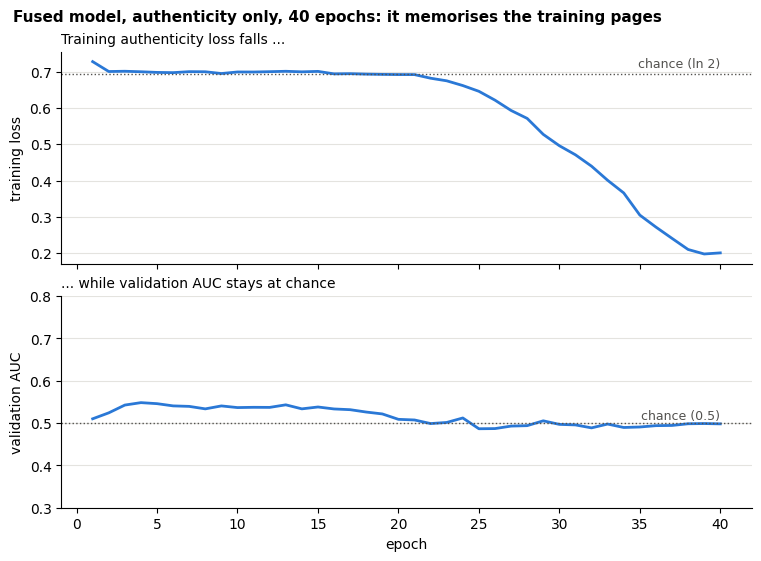

In [14]:
long = histories['fused_auth_long']
fig, (top, bottom) = plt.subplots(2, 1, figsize=(7.5, 5.5), sharex=True, constrained_layout=True)
top.plot(long.epoch, long.train_auth_loss, color='#2a78d6', linewidth=2)
top.axhline(np.log(2), color='#52514e', linestyle=':', linewidth=1)
top.text(40, np.log(2) + 0.02, 'chance (ln 2)', color='#52514e', fontsize=9, ha='right')
top.set_ylabel('training loss')
top.set_title('Training authenticity loss falls ...', loc='left', fontsize=10)
bottom.plot(long.epoch, long.val_auth_auc, color='#2a78d6', linewidth=2)
bottom.axhline(0.5, color='#52514e', linestyle=':', linewidth=1)
bottom.text(40, 0.51, 'chance (0.5)', color='#52514e', fontsize=9, ha='right')
bottom.set_ylim(0.3, 0.8)
bottom.set_ylabel('validation AUC')
bottom.set_xlabel('epoch')
bottom.set_title('... while validation AUC stays at chance', loc='left', fontsize=10)
for ax in (top, bottom):
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', color='#e4e3df')
fig.suptitle('Fused model, authenticity only, 40 epochs: it memorises the training pages', x=0.01, ha='left',
             fontweight='bold', fontsize=11)
fig.savefig(FIGURES_DIR / 'diagnostic_auth_long.png', dpi=200, bbox_inches='tight')
plt.show()